# 08 · The exothermic CSTR: multiple steady states and stability

A stirred tank with an exothermic reaction can sit at more than one steady state for the same feed: a cold,
low-conversion state, a hot, high-conversion state, and an unstable one between them. Which one the reactor
finds depends on its history; a small change in feed temperature can make it jump ("ignite") or collapse
("extinguish"), with hysteresis. This notebook builds the heat-generation and heat-removal curves, finds the
steady states, tests their stability, and maps the ignition-extinction diagram of the course reaction.

**What you will learn**
- construct heat-generation and heat-removal curves
- find all steady states and classify their stability
- simulate transients to see ignition and extinction
- map the hysteresis and draw design conclusions

**Before you start:** notebooks 04 and 07  ·  **Time:** about 75 min

In [1]:
try:                      # on Google Colab (or anywhere engreact is missing): install it from GitHub
    import engreact
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "git+https://github.com/ktwyw/engreact"], check=True)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from engreact import energy
plt.rcParams.update({"figure.figsize": (7, 4), "figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

import inspect
from IPython.display import Code

def show_source(obj):
    """Display the source code of a library function or class."""
    return Code(inspect.getsource(obj), language="python")

def heading(text):
    print(f"\n{text}\n" + "=" * len(text))

## Heat generated and heat removed

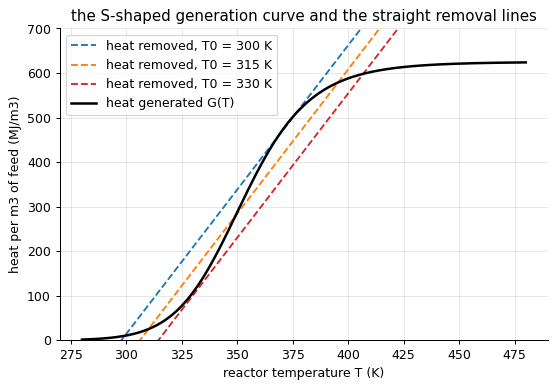

T0 = 300 K: steady states at T = [299, 368, 376] K, X = [0.016, 0.729, 0.811], stable [True, False, True]
T0 = 315 K: steady states at T = [310, 349, 395] K, X = [0.04, 0.446, 0.926], stable [True, False, True]
T0 = 330 K: steady states at T = [407] K, X = [0.957], stable [True]


In [2]:
k0, Ea, dH, C_A0, cp_vol = 5.0e7, 68e3, -250e3, 2500.0, 3.6e6
tau, kappa, T_a = 240.0, 0.8, 295.0
T = np.linspace(280, 480, 400)
fig, ax = plt.subplots(figsize=(7, 4.5))
for T0, col in ((300.0, "C0"), (315.0, "C1"), (330.0, "C3")):
    c = energy.cstr_heat_curves(k0, Ea, dH, C_A0, T0, tau, cp_vol, T, kappa, T_a)
    ax.plot(T, c["R"] / 1e6, color=col, ls="--", label=f"heat removed, T0 = {T0:.0f} K")
ax.plot(T, c["G"] / 1e6, "k", lw=2, label="heat generated G(T)")
ax.set(xlabel="reactor temperature T (K)", ylabel="heat per m3 of feed (MJ/m3)", ylim=(0, 700), title="the S-shaped generation curve and the straight removal lines"); ax.legend(); plt.show()
for T0 in (300.0, 315.0, 330.0):
    ss = energy.cstr_steady_states(k0, Ea, dH, C_A0, T0, tau, cp_vol, kappa, T_a, T_range=(250.0, 800.0))
    print(f"T0 = {T0:.0f} K: steady states at T = {[round(t) for t in ss['T']]} K, X = {[round(x, 3) for x in ss['X']]}, stable {ss['stable']}")

Heat generation follows the conversion, an S-curve in temperature (Arrhenius below, complete conversion
above); heat removal is a straight line through the feed and coolant temperatures. Their intersections are
the steady states: three at 300 K (the two upper ones close together, just inside the fold), three at 315 K
well separated, and a single hot state at 330 K, where the removal line has moved past the S-curve's knee.

## Stability

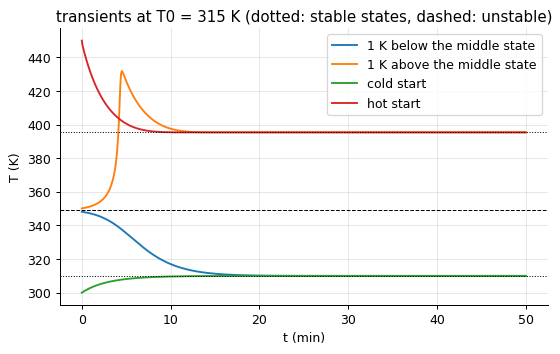

In [3]:
ss = energy.cstr_steady_states(k0, Ea, dH, C_A0, 315.0, tau, cp_vol, kappa, T_a, T_range=(250.0, 800.0))
t = np.linspace(0, 3000, 600)
fig, ax = plt.subplots()
for T_init, lbl in ((ss["T"][1] - 1, "1 K below the middle state"), (ss["T"][1] + 1, "1 K above the middle state"), (300.0, "cold start"), (450.0, "hot start")):
    C_init = C_A0 * (1 - ss["X"][1]) if "middle" in lbl else (C_A0 if "cold" in lbl else 0.0)
    un = energy.cstr_unsteady(k0, Ea, dH, C_A0, 315.0, tau, cp_vol, t, C_init, T_init, UA_over_Vcp=kappa / tau, T_a=T_a)
    ax.plot(t / 60, un["T"], label=lbl)
for T_ss, st in zip(ss["T"], ss["stable"]):
    ax.axhline(T_ss, color="k", ls=":" if st else "--", lw=0.8)
ax.set(xlabel="t (min)", ylabel="T (K)", title="transients at T0 = 315 K (dotted: stable states, dashed: unstable)"); ax.legend(); plt.show()

Start one degree below the middle state and the reactor cools to the extinguished branch; one degree above
and it ignites to 400 K. The middle state is a knife edge: at it, heat generation rises faster with
temperature than heat removal, so any deviation grows. The slope test $dG/dT < dR/dT$ is the necessary
condition for stability, and the transient integration is the proof.

## Ignition and extinction: hysteresis

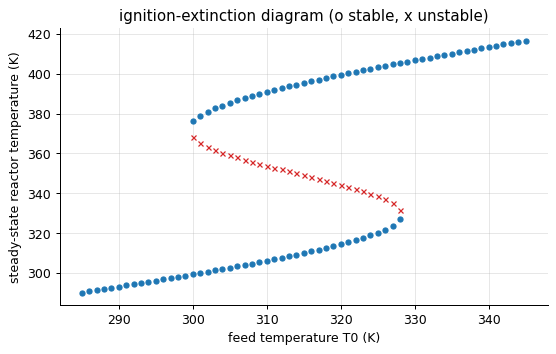

three steady states for T0 between 300 and 328 K: ignition on heating at about 328 K, extinction on cooling at about 300 K


In [4]:
T0s = np.linspace(285, 345, 61)
ie = energy.ignition_extinction(k0, Ea, dH, C_A0, tau, cp_vol, T0s, kappa, T_a)
fig, ax = plt.subplots()
for T0, Ts, sts in zip(ie["T0"], ie["T_ss"], ie["stable"]):
    for T_, st in zip(Ts, sts):
        ax.plot(T0, T_, "o" if st else "x", color="C0" if st else "C3", ms=4)
ax.set(xlabel="feed temperature T0 (K)", ylabel="steady-state reactor temperature (K)", title="ignition-extinction diagram (o stable, x unstable)"); plt.show()
n_ss = np.array([len(Ts) for Ts in ie["T_ss"]])
multi = T0s[n_ss == 3]
print(f"three steady states for T0 between {multi.min():.0f} and {multi.max():.0f} K: ignition on heating at about {multi.max():.0f} K, extinction on cooling at about {multi.min():.0f} K")

Raise the feed temperature slowly and the reactor stays cold until the upper limit of the multiplicity
region, then ignites; cool it back and it stays hot until the lower limit, then extinguishes. Between the
two, the state depends on history. Plant operators know this as "the reactor lit off" and "we lost the
reaction"; the diagram tells them where the edges are.

## Design implications

In [5]:
for kappa_ in (0.0, 0.8, 3.0):
    T0s = np.linspace(280, 400, 121)
    ie = energy.ignition_extinction(k0, Ea, dH, C_A0, tau, cp_vol, T0s, kappa_, T_a)
    n = np.array([len(Ts) for Ts in ie["T_ss"]])
    band = T0s[n == 3]
    print(f"kappa = UA/(v0 rho cp) = {kappa_}: " + (f"multiplicity for T0 in [{band.min():.0f}, {band.max():.0f}] K" if band.size else "no multiplicity in this range"))

kappa = UA/(v0 rho cp) = 0.0: multiplicity for T0 in [280, 304] K
kappa = UA/(v0 rho cp) = 0.8: multiplicity for T0 in [300, 328] K
kappa = UA/(v0 rho cp) = 3.0: no multiplicity in this range


More cooling (a larger $\kappa$) shrinks or removes the multiplicity region; so does a smaller residence time
or a more dilute feed. A reactor designed to run on the ignited branch must be started deliberately (heated
feed, then cooled) and protected against extinction; one designed for the low branch must be protected
against ignition. Either way, the operating point should sit far from the fold - which is what the
ignition-extinction diagram is for.

## Inside the algorithm: the heat-generation curve

In [6]:
from engreact import kinetics
T_ = 350.0
kk = kinetics.arrhenius(k0, Ea, T_)
X_ = kk * tau / (1 + kk * tau)
print("by hand: G =", (-dH) * C_A0 * X_ / 1e6, "MJ/m3; library:", float(energy.cstr_heat_curves(k0, Ea, dH, C_A0, 315.0, tau, cp_vol, T_, kappa, T_a)["G"]) / 1e6)

by hand: G = 287.70412223929526 MJ/m3; library: 287.70412223929526


## Exercises
1. Halve the residence time to 120 s and repeat the ignition-extinction map. Does multiplicity survive? Now double the feed concentration instead. Explain both results with the adiabatic temperature rise and the Damkohler number.
2. Find the feed temperature range over which the reactor can be operated on the *ignited* branch at 240 s with kappa = 0.8, and the start-up procedure (feed temperature schedule) that gets it there from a cold start without exceeding 420 K.
3. **Implement it yourself:** write the slope stability test dG/dT < dR/dT with a finite difference and apply it to the three steady states at T0 = 315 K; compare with the library's verdicts.